# BrainTumorAI — Reliable U-Net Segmentation (Clean Training Notebook)

This notebook replaces the duplicated/overridden pipeline in the previous notebook with one consistent workflow:
- validates image–mask pairing by filename stem;
- splits only the provided training set into train/validation;
- uses the same preprocessing for train, validation, and test;
- applies paired augmentation **only to training**;
- trains a lightweight U-Net with a real BCE + soft-Dice loss;
- saves the best validation checkpoint;
- selects a probability threshold using validation data only;
- evaluates the locked test set once and reports per-image failures.

**Important:** segmentation metrics are not a medical diagnosis. Review masks and predictions with a qualified expert before any clinical use.

## 1. Imports and reproducibility

In [8]:
from pathlib import Path
import os
import random
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# Optional: let TensorFlow grow GPU memory as needed.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

TensorFlow: 2.10.1
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Resolve the project and dataset paths

In [9]:
# Works when launched from the notebooks/ directory or from the project root.
cwd = Path.cwd().resolve()
candidate_roots = [cwd, cwd.parent, *cwd.parents]
PROJECT_ROOT = next(
    (p for p in candidate_roots if (p / "data" / "segmentation_task").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/segmentation_task. Put this notebook in "
        "BrainTumorAI/notebooks/ or update PROJECT_ROOT manually."
    )

SEG_DIR = PROJECT_ROOT / "data" / "segmentation_task"
TRAIN_IMAGE_DIR = SEG_DIR / "train" / "images"
TRAIN_MASK_DIR  = SEG_DIR / "train" / "masks"
TEST_IMAGE_DIR  = SEG_DIR / "test" / "images"
TEST_MASK_DIR   = SEG_DIR / "test" / "masks"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "segmentation"
MODEL_DIR = PROJECT_ROOT / "models" / "segmentation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "unet_clean_augmented_best.keras"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
VAL_REPORT_PATH = OUTPUT_DIR / "validation_diagnostics.csv"
TEST_REPORT_PATH = OUTPUT_DIR / "test_diagnostics.csv"

for p in [TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, TEST_IMAGE_DIR, TEST_MASK_DIR]:
    print(f"{p}: exists={p.exists()}")
    if not p.exists():
        raise FileNotFoundError(f"Required dataset folder not found: {p}")

print("Project root:", PROJECT_ROOT)

C:\Projects\BrainTumorAI\data\segmentation_task\train\images: exists=True
C:\Projects\BrainTumorAI\data\segmentation_task\train\masks: exists=True
C:\Projects\BrainTumorAI\data\segmentation_task\test\images: exists=True
C:\Projects\BrainTumorAI\data\segmentation_task\test\masks: exists=True
Project root: C:\Projects\BrainTumorAI


## 3. Pair images and masks safely

In [10]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
MASK_EXTENSIONS = {".png", ".tif", ".tiff"}

def list_files(folder, extensions):
    return sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    )

def pair_by_stem(image_dir, mask_dir):
    images = list_files(image_dir, IMAGE_EXTENSIONS)
    masks = list_files(mask_dir, MASK_EXTENSIONS)
    image_map = {p.stem: p for p in images}
    mask_map = {p.stem: p for p in masks}

    if len(image_map) != len(images):
        raise ValueError(f"Duplicate image stems found in {image_dir}")
    if len(mask_map) != len(masks):
        raise ValueError(f"Duplicate mask stems found in {mask_dir}")

    missing_masks = sorted(set(image_map) - set(mask_map))
    missing_images = sorted(set(mask_map) - set(image_map))
    print(f"Images: {len(images)} | Masks: {len(masks)}")
    print(f"Images without masks: {len(missing_masks)}")
    print(f"Masks without images: {len(missing_images)}")

    if missing_masks or missing_images:
        raise ValueError(
            f"Pairing mismatch in {image_dir.parent}. "
            f"Examples missing masks={missing_masks[:5]}, "
            f"missing images={missing_images[:5]}"
        )

    stems = sorted(image_map)
    return [image_map[s] for s in stems], [mask_map[s] for s in stems]

all_train_images, all_train_masks = pair_by_stem(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
test_images, test_masks = pair_by_stem(TEST_IMAGE_DIR, TEST_MASK_DIR)

assert all(a.stem == b.stem for a, b in zip(all_train_images, all_train_masks))
assert all(a.stem == b.stem for a, b in zip(test_images, test_masks))
print("All image-mask pairs match.")

Images: 3933 | Masks: 3933
Images without masks: 0
Masks without images: 0
Images: 860 | Masks: 860
Images without masks: 0
Masks without images: 0
All image-mask pairs match.


## 4. Inspect original pairs and mask encoding

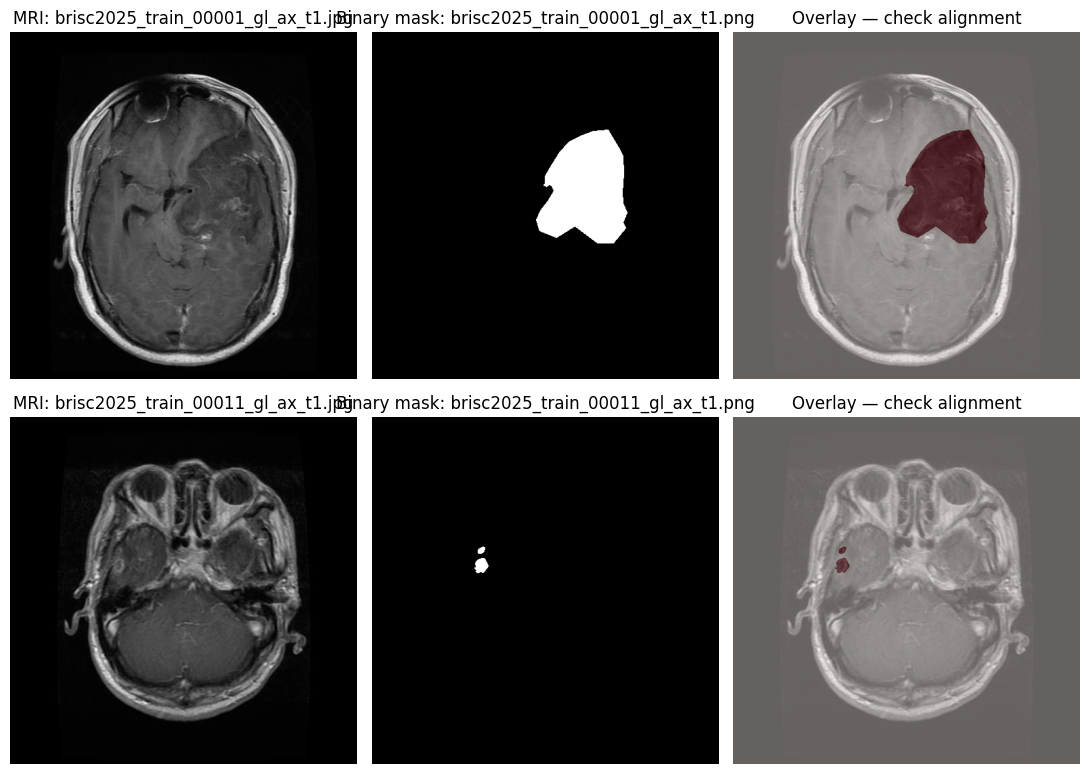

In [11]:
def show_original_pairs(image_paths, mask_paths, indices=None):
    if indices is None:
        indices = np.linspace(0, len(image_paths)-1, min(4, len(image_paths)), dtype=int)
    fig, axes = plt.subplots(len(indices), 3, figsize=(11, 4 * len(indices)))
    if len(indices) == 1:
        axes = np.expand_dims(axes, 0)
    for row, idx in enumerate(indices):
        with Image.open(image_paths[idx]) as im:
            image = np.array(im.convert("L"))
        with Image.open(mask_paths[idx]) as ma:
            mask = np.array(ma.convert("L"))
        binary = (mask >= 128).astype(np.uint8)
        axes[row, 0].imshow(image, cmap="gray")
        axes[row, 0].set_title(f"MRI: {image_paths[idx].name}")
        axes[row, 1].imshow(binary, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title(f"Binary mask: {mask_paths[idx].name}")
        axes[row, 2].imshow(image, cmap="gray")
        axes[row, 2].imshow(binary, cmap="Reds", alpha=0.4, vmin=0, vmax=1)
        axes[row, 2].set_title("Overlay — check alignment")
        for ax in axes[row]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_original_pairs(all_train_images, all_train_masks, indices=[0, min(10, len(all_train_images)-1)])

**Stop here if the masks do not overlap the tumor in the MRI.** The binary threshold below assumes foreground mask pixels are encoded at 128 or above. If your mask format differs, inspect the raw mask values and change the threshold deliberately.

In [12]:
with Image.open(all_train_masks[0]) as sample_mask:
    raw = np.array(sample_mask.convert("L"))
values, counts = np.unique(raw, return_counts=True)
print("Sample mask unique values (first 30):", values[:30])
print("Mask dimensions:", raw.shape)
print("Binary foreground fraction:", float((raw >= 128).mean()))

Sample mask unique values (first 30): [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Mask dimensions: (512, 512)
Binary foreground fraction: 0.062351226806640625


## 5. Train/validation split (test set stays untouched)

In [13]:
train_image_paths, val_image_paths, train_mask_paths, val_mask_paths = train_test_split(
    all_train_images,
    all_train_masks,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

assert all(a.stem == b.stem for a, b in zip(train_image_paths, train_mask_paths))
assert all(a.stem == b.stem for a, b in zip(val_image_paths, val_mask_paths))

print("Train pairs:", len(train_image_paths))
print("Validation pairs:", len(val_image_paths))
print("Held-out test pairs:", len(test_images))

Train pairs: 3146
Validation pairs: 787
Held-out test pairs: 860


## 6. Consistent preprocessing and paired augmentation

In [14]:
IMG_SIZE = 256
BATCH_SIZE = 4  # If GPU OOM occurs, change to 2 and rebuild the datasets.

def load_and_preprocess(image_path, mask_path):
    # Convert paths to TensorFlow strings
    image_path = tf.convert_to_tensor(image_path, dtype=tf.string)
    mask_path = tf.convert_to_tensor(mask_path, dtype=tf.string)

    # Read grayscale MRI
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])

    # Read grayscale tumor mask
    mask_bytes = tf.io.read_file(mask_path)
    mask = tf.io.decode_image(
        mask_bytes,
        channels=1,
        expand_animations=False
    )
    mask.set_shape([None, None, 1])

    # Resize while preserving aspect ratio
    image = tf.image.resize_with_pad(
        image, IMG_SIZE, IMG_SIZE, method="bilinear"
    )
    mask = tf.image.resize_with_pad(
        mask, IMG_SIZE, IMG_SIZE, method="nearest"
    )

    # Normalize MRI
    image = tf.cast(image, tf.float32) / 255.0

    # Convert mask to float BEFORE thresholding
    mask = tf.cast(mask, tf.float32)
    mask = tf.cast(mask >= 128.0, tf.float32)

    return (
        tf.ensure_shape(image, [IMG_SIZE, IMG_SIZE, 1]),
        tf.ensure_shape(mask, [IMG_SIZE, IMG_SIZE, 1])
    )

def augment_pair(image, mask):
    # Geometric transformation is applied identically to MRI and mask.
    # Horizontal flip is included; do not add arbitrary rotations without
    # confirming they preserve the dataset's anatomical orientation.
    flip = tf.random.uniform(()) > 0.5
    image = tf.cond(flip, lambda: tf.image.flip_left_right(image), lambda: image)
    mask = tf.cond(flip, lambda: tf.image.flip_left_right(mask), lambda: mask)

    # MRI-only intensity changes; never modify mask intensities geometrically.
    image = tf.image.random_brightness(image, max_delta=0.05)
    image = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    image = tf.clip_by_value(image, 0.0, 1.0)

    return (
        tf.ensure_shape(image, [IMG_SIZE, IMG_SIZE, 1]),
        tf.cast(mask >= 0.5, tf.float32)
    )

def create_segmentation_dataset(image_paths, mask_paths, shuffle=False,
                               batch_size=BATCH_SIZE, augment=False):
    image_paths = [str(p) for p in image_paths]
    mask_paths = [str(p) for p in mask_paths]
    if len(image_paths) != len(mask_paths):
        raise ValueError("Image and mask counts do not match.")

    ds = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(image_paths), seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(augment_pair, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_dataset = create_segmentation_dataset(
    train_image_paths, train_mask_paths, shuffle=True, augment=True
)
val_dataset = create_segmentation_dataset(
    val_image_paths, val_mask_paths, shuffle=False, augment=False
)
test_dataset = create_segmentation_dataset(
    test_images, test_masks, shuffle=False, augment=False
)

xb, yb = next(iter(train_dataset))
xv, yv = next(iter(val_dataset))

print("Train batch:", xb.shape, yb.shape)
print("Validation batch:", xv.shape, yv.shape)
print("Image range:", float(tf.reduce_min(xb)),
      float(tf.reduce_max(xb)))
print("Train mask values:", np.unique(yb.numpy()))
print("Validation mask values:", np.unique(yv.numpy()))

Train batch: (4, 256, 256, 1) (4, 256, 256, 1)
Validation batch: (4, 256, 256, 1) (4, 256, 256, 1)
Image range: 0.0 1.0
Train mask values: [0. 1.]
Validation mask values: [0. 1.]


## 7. Visually verify augmented image-mask pairs

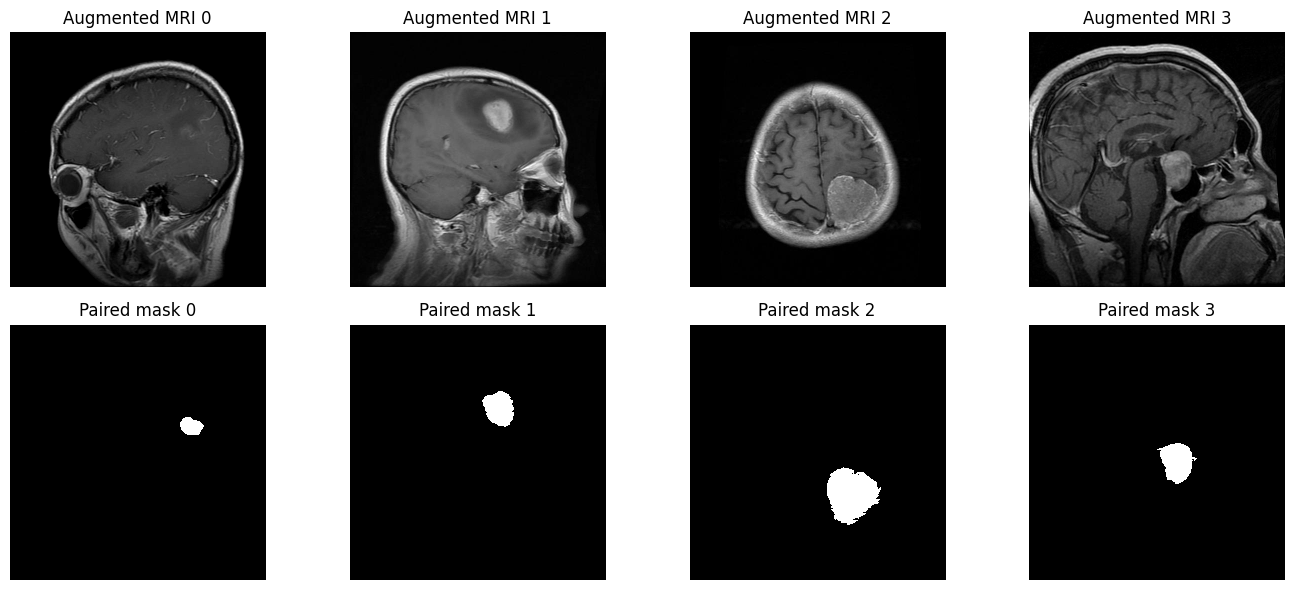

In [15]:
fig, axes = plt.subplots(2, min(4, int(xb.shape[0])), figsize=(14, 6))
for i in range(int(xb.shape[0])):
    axes[0, i].imshow(xb[i].numpy().squeeze(), cmap="gray")
    axes[0, i].set_title(f"Augmented MRI {i}")
    axes[1, i].imshow(yb[i].numpy().squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title(f"Paired mask {i}")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

## 8. Lightweight U-Net with regularization

In [16]:
def conv_block(x, filters, dropout_rate=0.0):
    x = tf.keras.layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal"
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)

    x = tf.keras.layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal"
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)

    if dropout_rate:
        x = tf.keras.layers.SpatialDropout2D(dropout_rate)(x)
    return x

def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 1), base_filters=24):
    inputs = tf.keras.Input(shape=input_shape)

    c1 = conv_block(inputs, base_filters)
    p1 = tf.keras.layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, base_filters * 2)
    p2 = tf.keras.layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, base_filters * 4, dropout_rate=0.05)
    p3 = tf.keras.layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, base_filters * 8, dropout_rate=0.10)
    p4 = tf.keras.layers.MaxPooling2D()(c4)

    b = conv_block(p4, base_filters * 16, dropout_rate=0.15)

    u4 = tf.keras.layers.Conv2DTranspose(base_filters * 8, 2, strides=2, padding="same")(b)
    u4 = tf.keras.layers.Concatenate()([u4, c4])
    d4 = conv_block(u4, base_filters * 8, dropout_rate=0.10)

    u3 = tf.keras.layers.Conv2DTranspose(base_filters * 4, 2, strides=2, padding="same")(d4)
    u3 = tf.keras.layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, base_filters * 4, dropout_rate=0.05)

    u2 = tf.keras.layers.Conv2DTranspose(base_filters * 2, 2, strides=2, padding="same")(d3)
    u2 = tf.keras.layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, base_filters * 2)

    u1 = tf.keras.layers.Conv2DTranspose(base_filters, 2, strides=2, padding="same")(d2)
    u1 = tf.keras.layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, base_filters)

    outputs = tf.keras.layers.Conv2D(1, 1, activation="sigmoid", name="tumor_probability")(d1)
    return tf.keras.Model(inputs, outputs, name="BrainTumorAI_Lightweight_UNet")

tf.keras.backend.clear_session()
gc.collect()
model = build_unet()
model.summary()
print("Output shape:", model.output_shape)

Model: "BrainTumorAI_Lightweight_UNet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 24  216         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 256, 256, 24  96         ['conv2d[0][0]']                 
 alization)                     )                                     

## 9. Loss and thresholded metrics

In [17]:
def soft_dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true = tf.reshape(y_true, [tf.shape(y_true)[0], -1])
    y_pred = tf.reshape(y_pred, [tf.shape(y_pred)[0], -1])
    intersection = tf.reduce_sum(y_true * y_pred, axis=1)
    denom = tf.reduce_sum(y_true, axis=1) + tf.reduce_sum(y_pred, axis=1)
    dice = (2.0 * intersection + smooth) / (denom + smooth)
    return 1.0 - tf.reduce_mean(dice)

def bce_dice_loss(y_true, y_pred):
    # Both terms matter: BCE encourages pixelwise probabilities;
    # soft Dice directly rewards overlap for small foreground regions.
    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_true, y_pred)
    )
    return bce + soft_dice_loss(y_true, y_pred)

def dice_coefficient(y_true, y_pred, threshold=0.5, smooth=1e-6):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= threshold, tf.float32)
    y_true = tf.reshape(y_true, [tf.shape(y_true)[0], -1])
    y_pred = tf.reshape(y_pred, [tf.shape(y_pred)[0], -1])
    inter = tf.reduce_sum(y_true * y_pred, axis=1)
    denom = tf.reduce_sum(y_true, axis=1) + tf.reduce_sum(y_pred, axis=1)
    return tf.reduce_mean((2.0 * inter + smooth) / (denom + smooth))

def iou_score(y_true, y_pred, threshold=0.5, smooth=1e-6):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= threshold, tf.float32)
    y_true = tf.reshape(y_true, [tf.shape(y_true)[0], -1])
    y_pred = tf.reshape(y_pred, [tf.shape(y_pred)[0], -1])
    inter = tf.reduce_sum(y_true * y_pred, axis=1)
    union = tf.reduce_sum(y_true, axis=1) + tf.reduce_sum(y_pred, axis=1) - inter
    return tf.reduce_mean((inter + smooth) / (union + smooth))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=bce_dice_loss,
    metrics=[dice_coefficient, iou_score]
)

# One-batch smoke test before a full run.
smoke = model.train_on_batch(xb, yb, return_dict=True)
print("One-batch smoke test:", smoke)

One-batch smoke test: {'loss': 1.8009395599365234, 'dice_coefficient': 0.03514450415968895, 'iou_score': 0.017985831946134567}


## 10. Train and save the best validation checkpoint

In [18]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

EPOCHS = 40
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

pd.DataFrame(history.history).to_csv(HISTORY_PATH, index=False)
print("Best checkpoint exists:", BEST_MODEL_PATH.exists())
print("Checkpoint path:", BEST_MODEL_PATH.resolve())

Epoch 1/40
787/787 [==============================] - ETA: 0s - loss: 1.2378 - dice_coefficient: 0.3495 - iou_score: 0.2638
Epoch 1: val_dice_coefficient improved from -inf to 0.38320, saving model to C:\Projects\BrainTumorAI\models\segmentation\unet_clean_augmented_best.keras
787/787 [==============================] - 76s 95ms/step - loss: 1.2378 - dice_coefficient: 0.3495 - iou_score: 0.2638 - val_loss: 1.1384 - val_dice_coefficient: 0.3832 - val_iou_score: 0.2697 - lr: 1.0000e-04
Epoch 2/40
786/787 [============================>.] - ETA: 0s - loss: 0.9686 - dice_coefficient: 0.5915 - iou_score: 0.4783
Epoch 2: val_dice_coefficient improved from 0.38320 to 0.46560, saving model to C:\Projects\BrainTumorAI\models\segmentation\unet_clean_augmented_best.keras
787/787 [==============================] - 72s 92ms/step - loss: 0.9685 - dice_coefficient: 0.5917 - iou_score: 0.4784 - val_loss: 0.9394 - val_dice_coefficient: 0.4656 - val_iou_score: 0.3423 - lr: 1.0000e-04
Epoch 3/40
786/787 [=

## 11. Plot learning curves

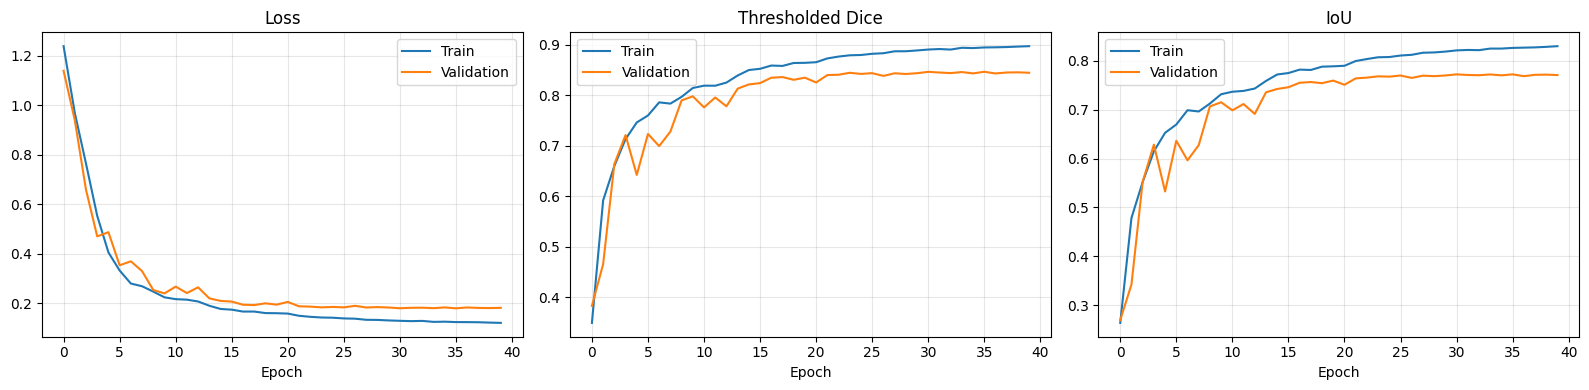

In [19]:
hist = history.history
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(hist["loss"], label="Train")
axes[0].plot(hist["val_loss"], label="Validation")
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(True, alpha=.3)

axes[1].plot(hist["dice_coefficient"], label="Train")
axes[1].plot(hist["val_dice_coefficient"], label="Validation")
axes[1].set_title("Thresholded Dice"); axes[1].legend(); axes[1].grid(True, alpha=.3)

axes[2].plot(hist["iou_score"], label="Train")
axes[2].plot(hist["val_iou_score"], label="Validation")
axes[2].set_title("IoU"); axes[2].legend(); axes[2].grid(True, alpha=.3)
for ax in axes:
    ax.set_xlabel("Epoch")
plt.tight_layout()
plt.show()

## 12. Load the saved best checkpoint

In [20]:
# compile=False avoids needing to deserialize the custom loss for inference.
best_model = tf.keras.models.load_model(BEST_MODEL_PATH, compile=False)
print("Loaded:", BEST_MODEL_PATH.resolve())
print("Input:", best_model.input_shape, "Output:", best_model.output_shape)

Loaded: C:\Projects\BrainTumorAI\models\segmentation\unet_clean_augmented_best.keras
Input: (None, 256, 256, 1) Output: (None, 256, 256, 1)


## 13. Tune the threshold on validation data only

The default threshold of 0.5 is not always optimal. This cell evaluates several thresholds on validation data and chooses the threshold with the best **mean per-image Dice**. This is a model-selection step, so it must not use test labels.

In [21]:
def collect_predictions(model, dataset):
    xs, ys, ps = [], [], []
    for images, masks in dataset:
        probs = model.predict(images, verbose=0)
        xs.append(images.numpy())
        ys.append(masks.numpy())
        ps.append(probs)
    return np.concatenate(xs), np.concatenate(ys), np.concatenate(ps)

val_x, val_y, val_prob = collect_predictions(best_model, val_dataset)

def per_image_scores(y_true, y_prob, threshold=0.5, smooth=1e-7):
    true = np.asarray(y_true).squeeze(axis=-1) >= 0.5
    pred = np.asarray(y_prob).squeeze(axis=-1) >= threshold
    true = true.reshape((true.shape[0], -1))
    pred = pred.reshape((pred.shape[0], -1))
    inter = np.logical_and(true, pred).sum(axis=1)
    denom = true.sum(axis=1) + pred.sum(axis=1)
    dice = np.where(denom > 0, (2 * inter + smooth) / (denom + smooth), 1.0)
    union = true.sum(axis=1) + pred.sum(axis=1) - inter
    iou = np.where(union > 0, (inter + smooth) / (union + smooth), 1.0)
    return dice, iou

threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    ds, ios = per_image_scores(val_y, val_prob, float(threshold))
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "mean_dice": float(ds.mean()),
        "median_dice": float(np.median(ds)),
        "mean_iou": float(ios.mean()),
        "cases_dice_below_0_5": int((ds < 0.5).sum())
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)
BEST_THRESHOLD = float(
    threshold_table.sort_values(["mean_dice", "median_dice"], ascending=False).iloc[0]["threshold"]
)
print("Chosen validation threshold:", BEST_THRESHOLD)

,threshold,mean_dice,median_dice,mean_iou,cases_dice_below_0_5
0,0.20,0.845572,0.922287,0.770504,50
1,0.25,0.845826,0.922440,0.771047,50
2,0.30,0.845986,0.922752,0.771411,50
3,0.35,0.846082,0.923683,0.771633,49
4,0.40,0.846107,0.924492,0.771806,50
5,0.45,0.846025,0.924218,0.771837,50
6,0.50,0.846061,0.924414,0.772031,50
7,0.55,0.845855,0.923986,0.771796,50
8,0.60,0.845779,0.924370,0.771778,50
9,0.65,0.845530,0.923077,0.771467,50


Chosen validation threshold: 0.4


## 14. Validation error report

In [22]:
val_dice, val_iou = per_image_scores(val_y, val_prob, BEST_THRESHOLD)
val_true = val_y.squeeze(-1) >= 0.5
val_pred = val_prob.squeeze(-1) >= BEST_THRESHOLD

val_records = []
for i in range(len(val_y)):
    true_pixels = int(val_true[i].sum())
    pred_pixels = int(val_pred[i].sum())
    val_records.append({
        "index": i,
        "image": str(val_image_paths[i]),
        "mask": str(val_mask_paths[i]),
        "true_pixels": true_pixels,
        "predicted_pixels": pred_pixels,
        "max_probability": float(val_prob[i].max()),
        "mean_probability": float(val_prob[i].mean()),
        "dice": float(val_dice[i]),
        "iou": float(val_iou[i]),
        "error_type": (
            "missed_tumor" if true_pixels > 0 and pred_pixels == 0
            else "possible_oversegmentation" if pred_pixels > max(2 * true_pixels, true_pixels + 100)
            else "poor_overlap" if val_dice[i] < 0.5
            else "reasonable_overlap"
        )
    })

val_report = pd.DataFrame(val_records).sort_values("dice")
val_report.to_csv(VAL_REPORT_PATH, index=False)
display(val_report.head(20))
print("Mean validation Dice:", round(float(val_dice.mean()), 4))
print("Median validation Dice:", round(float(np.median(val_dice)), 4))
print("Cases Dice < 0.5:", int((val_dice < 0.5).sum()))
print("Report saved:", VAL_REPORT_PATH.resolve())

,index,image,mask,true_pixels,predicted_pixels,max_probability,mean_probability,dice,iou,error_type
114,114,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,800,2095,0.999864,0.031510,3.454231e-11,3.454231e-11,possible_oversegmentation
590,590,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,508,1535,0.999845,0.022920,4.894763e-11,4.894763e-11,possible_oversegmentation
551,551,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,1490,132,0.989257,0.002012,6.165228e-11,6.165228e-11,poor_overlap
259,259,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,944,580,0.999961,0.008828,6.561680e-11,6.561680e-11,poor_overlap
421,421,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,701,502,0.999805,0.007510,8.312552e-11,8.312552e-11,poor_overlap
747,747,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,1197,0,0.346640,0.000159,8.354219e-11,8.354219e-11,missed_tumor
299,299,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,372,486,0.999909,0.007321,1.165501e-10,1.165501e-10,poor_overlap
496,496,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,243,585,0.997172,0.008629,1.207729e-10,1.207729e-10,possible_oversegmentation
254,254,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,816,0,0.006793,0.000022,1.225490e-10,1.225490e-10,missed_tumor
673,673,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,75,694,0.999944,0.010479,1.300390e-10,1.300390e-10,possible_oversegmentation


Mean validation Dice: 0.8461
Median validation Dice: 0.9245
Cases Dice < 0.5: 50
Report saved: C:\Projects\BrainTumorAI\outputs\segmentation\validation_diagnostics.csv


## 15. Visualize the worst validation cases

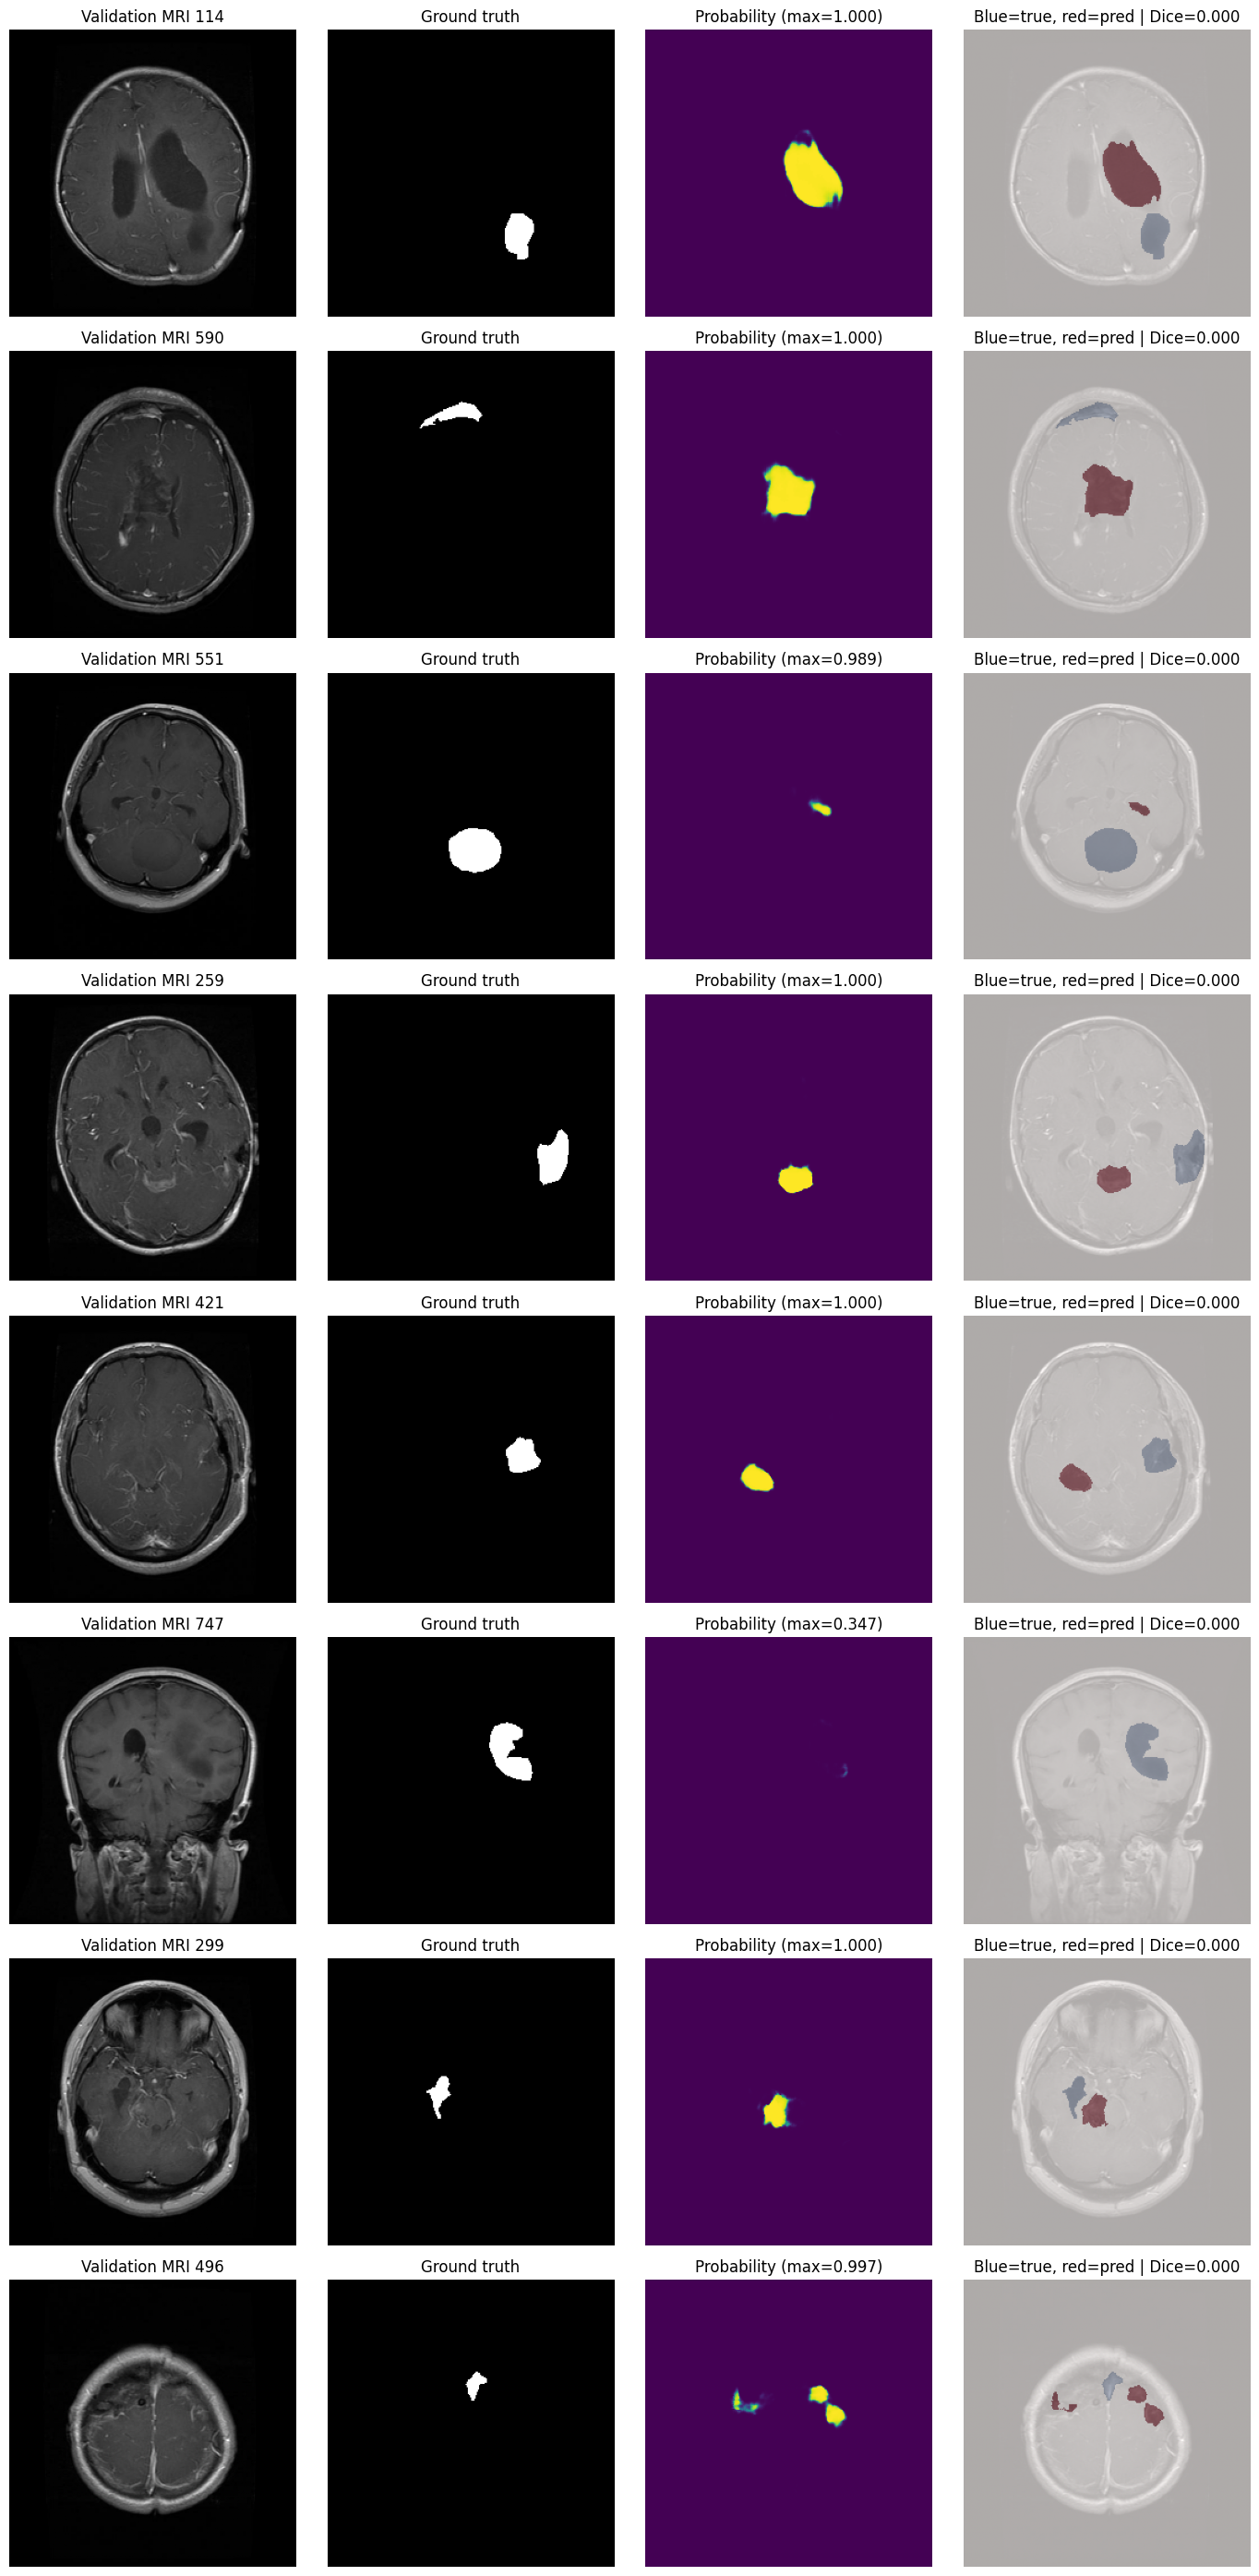

In [23]:
def show_cases(images, truths, probs, scores, indices, threshold, title_prefix="Validation"):
    n = len(indices)
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.5 * n))
    if n == 1:
        axes = np.expand_dims(axes, 0)
    for row, idx in enumerate(indices):
        img = images[idx].squeeze()
        truth = truths[idx].squeeze() >= 0.5
        prob = probs[idx].squeeze()
        pred = prob >= threshold

        axes[row, 0].imshow(img, cmap="gray")
        axes[row, 0].set_title(f"{title_prefix} MRI {idx}")
        axes[row, 1].imshow(truth, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground truth")
        axes[row, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
        axes[row, 2].set_title(f"Probability (max={prob.max():.3f})")
        axes[row, 3].imshow(img, cmap="gray")
        axes[row, 3].imshow(truth, cmap="Blues", alpha=0.45, vmin=0, vmax=1)
        axes[row, 3].imshow(pred, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
        axes[row, 3].set_title(f"Blue=true, red=pred | Dice={scores[idx]:.3f}")
        for ax in axes[row]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

worst_val_indices = np.argsort(val_dice)[:min(8, len(val_dice))]
show_cases(val_x, val_y, val_prob, val_dice, worst_val_indices, BEST_THRESHOLD)

## 16. Final held-out test evaluation

Do not tune the architecture, threshold, or preprocessing based on these test results. The test set is used here for final reporting only.

In [24]:
test_x, test_y, test_prob = collect_predictions(best_model, test_dataset)
test_dice, test_iou = per_image_scores(test_y, test_prob, BEST_THRESHOLD)

test_true = test_y.squeeze(-1) >= 0.5
test_pred = test_prob.squeeze(-1) >= BEST_THRESHOLD

test_records = []
for i in range(len(test_y)):
    tp = int(test_true[i].sum())
    pp = int(test_pred[i].sum())
    test_records.append({
        "index": i,
        "image": str(test_images[i]),
        "mask": str(test_masks[i]),
        "true_pixels": tp,
        "predicted_pixels": pp,
        "max_probability": float(test_prob[i].max()),
        "mean_probability": float(test_prob[i].mean()),
        "dice": float(test_dice[i]),
        "iou": float(test_iou[i]),
        "error_type": (
            "missed_tumor" if tp > 0 and pp == 0
            else "possible_oversegmentation" if pp > max(2 * tp, tp + 100)
            else "poor_overlap" if test_dice[i] < 0.5
            else "reasonable_overlap"
        )
    })

test_report = pd.DataFrame(test_records).sort_values("dice")
test_report.to_csv(TEST_REPORT_PATH, index=False)

print("FINAL TEST METRICS")
print(f"Mean Dice:   {test_dice.mean():.4f}")
print(f"Median Dice: {np.median(test_dice):.4f}")
print(f"Mean IoU:    {test_iou.mean():.4f}")
print(f"Dice < 0.5:  {(test_dice < 0.5).sum()} / {len(test_dice)}")
print(f"Missed tumors: {((test_true.reshape(len(test_true), -1).sum(axis=1) > 0) & (test_pred.reshape(len(test_pred), -1).sum(axis=1) == 0)).sum()}")
print("Test report:", TEST_REPORT_PATH.resolve())
display(test_report.head(20))

FINAL TEST METRICS
Mean Dice:   0.8515
Median Dice: 0.9291
Mean IoU:    0.7787
Dice < 0.5:  54 / 860
Missed tumors: 8
Test report: C:\Projects\BrainTumorAI\outputs\segmentation\test_diagnostics.csv


,index,image,mask,true_pixels,predicted_pixels,max_probability,mean_probability,dice,iou,error_type
44,44,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,3157,0,0.001220,0.000013,3.167564e-11,3.167564e-11,missed_tumor
280,280,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,1369,1062,0.999949,0.016030,4.113534e-11,4.113534e-11,poor_overlap
0,0,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,286,1417,0.999983,0.021415,5.871991e-11,5.871991e-11,possible_oversegmentation
58,58,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,1435,0,0.033257,0.000036,6.968641e-11,6.968641e-11,missed_tumor
95,95,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,269,1083,0.999651,0.016254,7.396450e-11,7.396450e-11,possible_oversegmentation
731,731,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,1145,206,0.999968,0.003076,7.401924e-11,7.401924e-11,poor_overlap
9,9,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,210,583,0.992983,0.008408,1.261034e-10,1.261034e-10,possible_oversegmentation
234,234,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,571,221,0.999650,0.003303,1.262626e-10,1.262626e-10,poor_overlap
59,59,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,733,0,0.011993,0.000022,1.364256e-10,1.364256e-10,missed_tumor
11,11,C:\Projects\BrainTumorAI\data\segmentation_tas...,C:\Projects\BrainTumorAI\data\segmentation_tas...,461,194,0.990222,0.002830,1.526718e-10,1.526718e-10,poor_overlap


## 17. Visualize worst held-out test cases

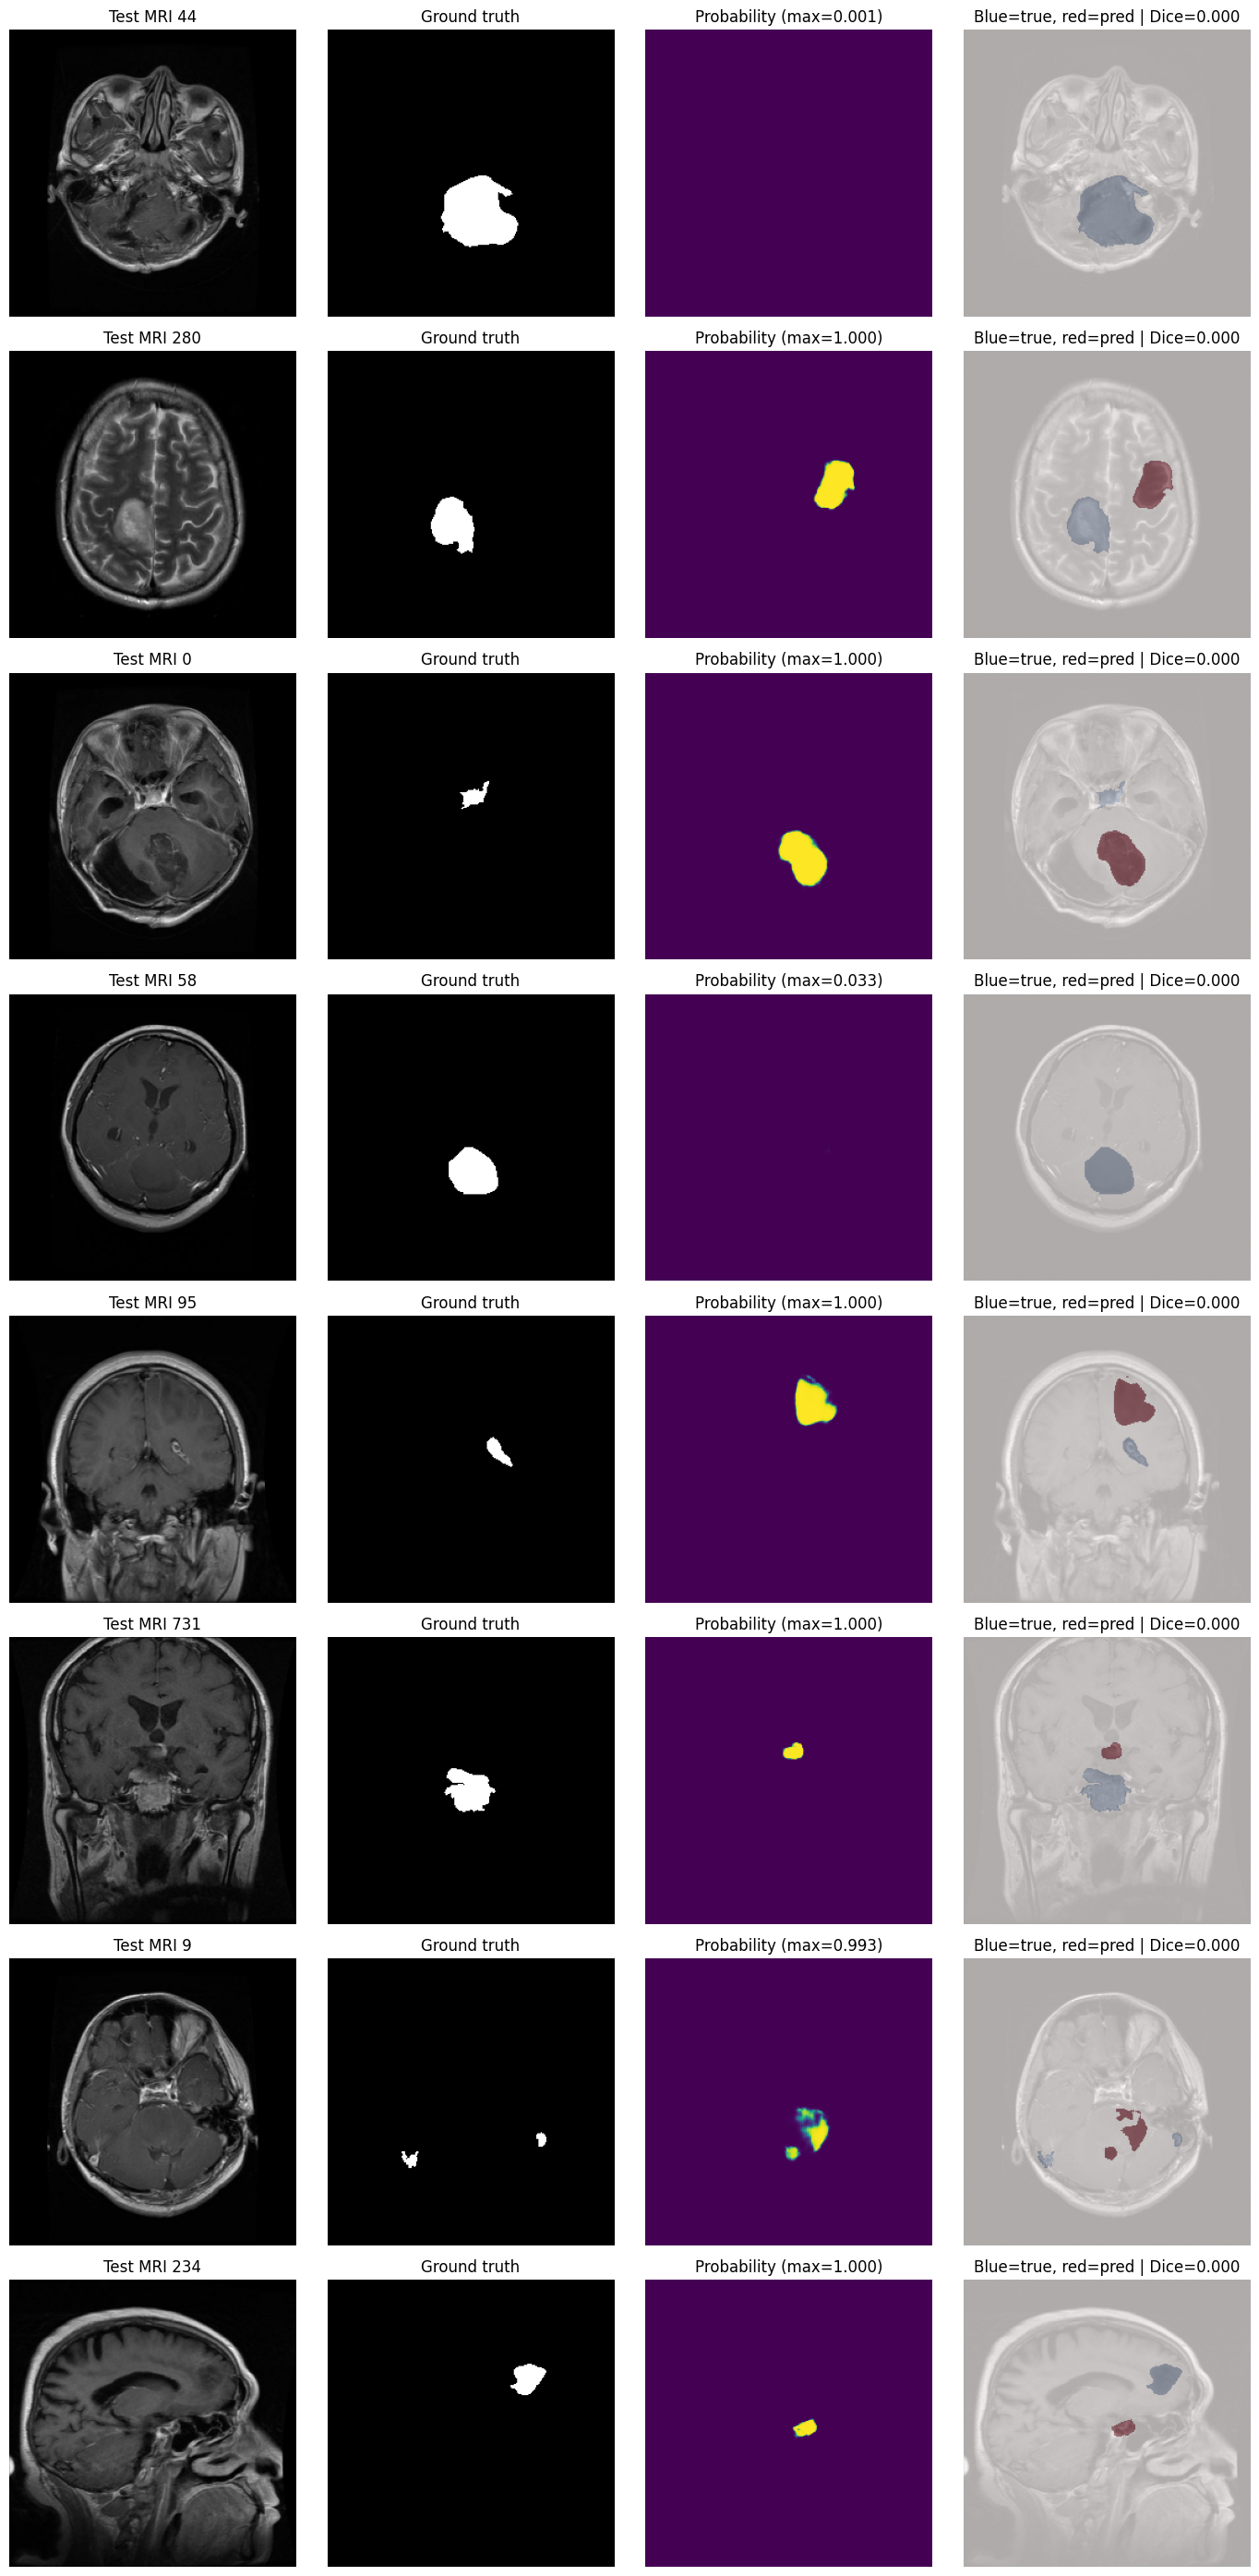

In [25]:
worst_test_indices = np.argsort(test_dice)[:min(8, len(test_dice))]
show_cases(test_x, test_y, test_prob, test_dice, worst_test_indices, BEST_THRESHOLD, title_prefix="Test")

## 18. Interpretation and next experiment

Prioritize the following in order:
1. Manually inspect the worst masks and confirm annotations are anatomically correct.
2. Compare missed-tumor cases with their raw masks and overlays. Do not assume every failure is a model problem; annotation quality and mask preprocessing matter.
3. Compare this clean run with the prior checkpoint using the **same split and same metric implementation**.
4. Only then run a controlled experiment with one change at a time (for example, stronger but anatomically safe augmentation, different base filter count, or a Tversky/Focal-Tversky loss).
5. Report mean and median per-image Dice, IoU, number of missed tumors, and the full distribution—not just the best cases.

A higher validation score is not guaranteed. This notebook is designed to make experiments more consistent and diagnostic, not to promise a particular accuracy.

In [45]:
from pathlib import Path
import tensorflow as tf

MODEL_PATH = Path(
    r"C:\Projects\BrainTumorAI\models\segmentation\unet_augmented_best.keras"
)

# Check that the model file exists
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

# Load the trained model
model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

# Display model information
print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Model parameters:", f"{model.count_params():,}")

Model loaded successfully!
Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)
Model parameters: 7,771,297
